# 프롬프트 엔지니어링 실습: 고객 문의 분류 틀에 JSON 검사와 버전 기록 붙이기

**이 노트북에서 할 일**

1. 04절 틀에 02절 과업 명세와 07절 JSON 출력 형식을 넣고, 07절 세 층 검사와 01절 기록 함수를 붙입니다.
2. 허용 이름이 셋인 버전 `v1` 틀에 텀블러 문의와 글꼴 문의를 채워 보내고, 결과를 봅니다(실행 1).
3. 허용 이름에 「기타」 한 낱말만 더한 `v2`로 같은 두 문의를 보내고, 두 실행을 비교합니다(실행 2).

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 읽는 데이터 파일은 없습니다.

인터넷 서비스에 요청을 모두 4번 보냅니다. 모두 `gpt-5.4-mini`이고, 실행 1과 실행 2에 2번씩입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만입니다.
요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

이 노트북은 파일을 만들거나 고치지 않습니다. 08절이 쓴 `runs` 폴더의 기록 파일도 건드리지 않습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.10.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch07-prompt-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

01~08절에서 쓴 이름과 문법만 씁니다. 강사와 함께 셀을 차례로 실행하며, 따로 내는 과제는 없습니다.

## 오늘 볼 그림

![맨 위 초록 상자 재료 02절 과업 명세 앞부분과 텀블러 문의 글꼴 문의가 초록 상자 버전 기록 v1 v2 허용 이름 글만 다름으로 이어지고, 파란 상자 build_prompt 04절 틀을 지나 ask_inquiry 문의 하나씩 화살표로 보라 상자 gpt-5.4-mini에 가며, 파란 상자 timed_invoke make_prompt_record 01절 기록 한 줄과 파란 상자 check_layers find_category 07절 세 층 검사를 거쳐 노란 상자 기록 한 줄 토큰 수 검사 결과 category로 가는 조립도](attachment:09-1-조립도.png)

위에서 아래로 읽습니다. 초록 상자는 노트북에서 만든 글과 버전 기록이고, 파란 상자는 노트북에서 정의한 함수입니다.
보라 상자는 요청을 받는 모델이고, 맨 아래 노란 상자가 요청마다 남기는 기록 한 줄입니다.
두 버전은 허용 이름 글만 다르고, 나머지 조립은 같습니다.
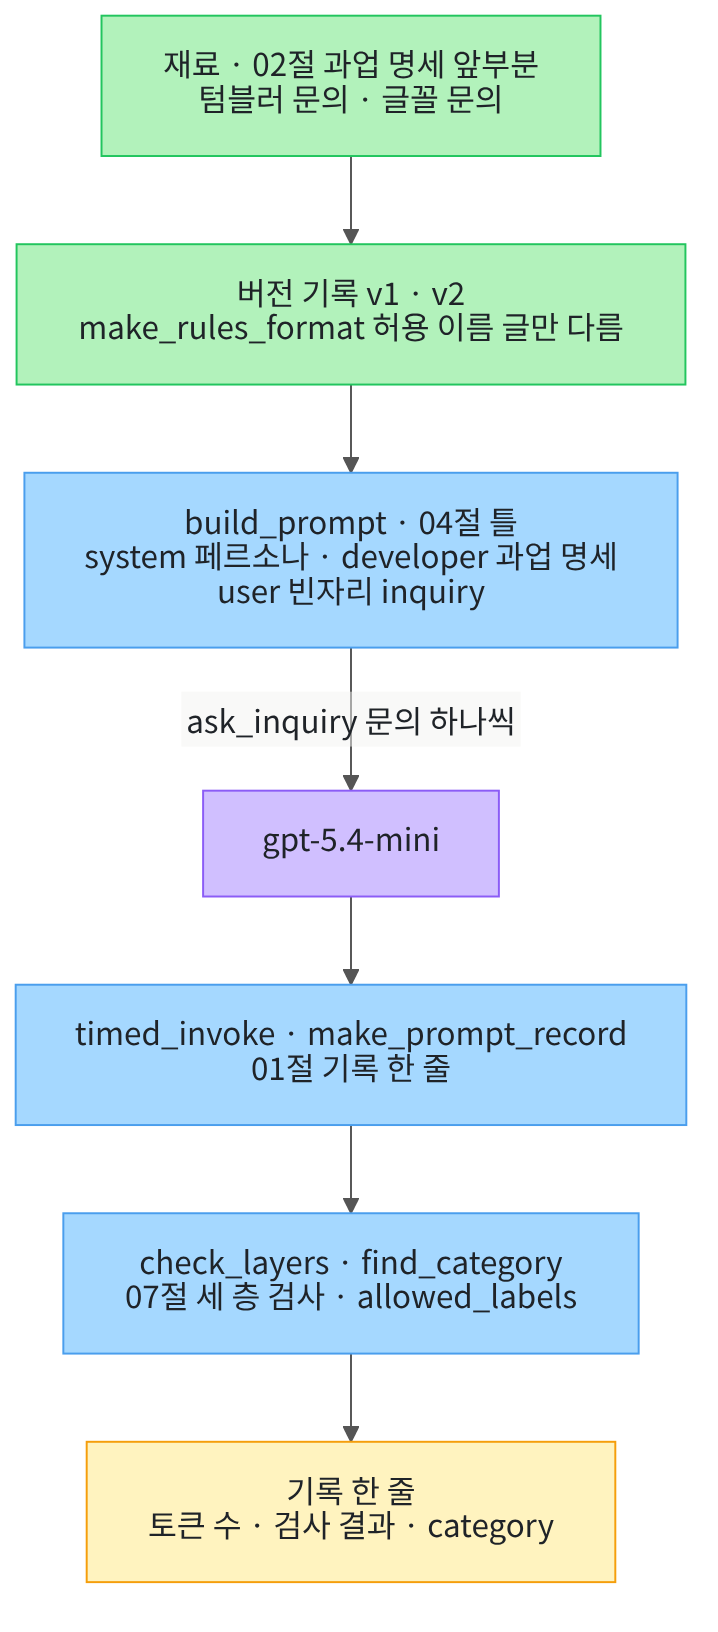

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0


openai: 3.10.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `langchain-core: 1.6.2`, `openai: 3.10.0` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

이번 실습에서 쓸 이름을 불러옵니다. 모듈 `json`은 07절, 모듈 `time`은 01절에서 불러왔습니다.
함수 `convert_to_messages`는 01절, 틀 클래스 `ChatPromptTemplate`은 04절에서 썼습니다.

In [2]:
# JSON 글을 읽는 모듈, 시간을 재는 모듈, 모델 객체·메시지 객체·틀을 만드는 도구를 불러옵니다
import json
import time

from langchain.chat_models import init_chat_model
from langchain_core.messages import convert_to_messages
from langchain_core.prompts import ChatPromptTemplate

01절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다.
실행마다 답 문장, 토큰 수, 걸린 초가 달라질 수 있습니다.

## 2. 실습 주제 — 고객 문의 분류 틀에 JSON 검사와 버전 기록 붙이기

상담 창구에 들어온 고객 문의를 프로그램이 분류하는 작은 분류기를 떠올립니다. 답은 07절처럼 JSON으로 받아, 프로그램이 값을 꺼냅니다.
메시지 목록은 04절 틀로 만들고, 고객 문의만 빈자리에 채웁니다. 요청마다 01절 기록 한 줄과 07절 세 층 검사 결과를 남깁니다.

07절 11절에서는 글꼴 문의의 답이 세 층을 모두 지났지만, category 값은 `배송`이었습니다.
허용 이름이 배송·교환·환불 셋뿐이라, 맞는 이름이 없는데도 셋 가운데 하나를 고른 답입니다.
그래서 이번 실습은 허용 이름에 「기타」를 더한 버전을 08절처럼 기록하고, 원래 버전과 비교합니다.

실행 1은 허용 이름이 셋인 `v1`, 실행 2는 「기타」를 더한 `v2`로 같은 두 문의를 보냅니다. 두 실행에서 바꾸는 값은 허용 이름 글 하나입니다.
03절 예시, 04절 대화 기록, 05절 근거 줄, 06절 표본 합의는 이번 실습에서 쓰지 않습니다.

## 3. 재료 만들기 — 과업 명세 앞부분과 문의 두 개

페르소나와 과업 명세의 목표·필수 정보·금지 사항은 02절과 같은 글입니다. 07절처럼 세 글을 줄바꿈으로 이어 과업 명세 앞부분을 만듭니다.
출력 형식은 4절에서 버전마다 따로 붙입니다.

문의는 01~08절의 텀블러 문의와, 03·07절에서 쓴 글꼴 문의 두 개입니다. 문의 이름과 글을 튜플로 묶어 목록에 담습니다.

실행 전에 예상합니다. 문의 수는 2일 것입니다.

In [5]:
# 02절과 같은 글로 과업 명세 앞부분을 만들고, 문의 이름과 글을 튜플로 묶어 목록에 담습니다
persona_text = "당신은 친절한 고객 상담원입니다."
goal_text = "고객 문의를 분류하고 필요한 다음 행동을 안내하세요."
required_text = "회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요."
forbidden_text = "근거 없는 보상은 약속하지 마세요."
task_start_text = goal_text + "\n" + required_text + "\n" + forbidden_text + "\n"
inquiry_text = "어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다."
font_inquiry_text = "뉴스레터 글꼴을 바꾸고 싶습니다."
inquiries = [("텀블러 문의", inquiry_text), ("글꼴 문의", font_inquiry_text)]
print("페르소나:", persona_text)
print("과업 명세 앞부분:")
print(task_start_text)
print("문의 수:", len(inquiries))

페르소나: 당신은 친절한 고객 상담원입니다.
과업 명세 앞부분:
고객 문의를 분류하고 필요한 다음 행동을 안내하세요.
회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요.
근거 없는 보상은 약속하지 마세요.

문의 수: 2


**결과 읽기** — 라벨 줄 `과업 명세 앞부분:` 아래에 목표·필수 정보·금지 사항 세 줄이 나옵니다.
글 끝에 줄바꿈을 하나 붙여 두어서 그 아래에 빈 줄이 하나 보입니다. 마지막 줄은 `문의 수: 2`입니다.

## 4. 재료 만들기 — 허용 이름만 다른 두 버전

출력 형식은 07절 「값 규칙」 출력 형식과 같은 네 문장입니다. 그 가운데 category 값의 허용 이름을 적는 자리만 인자로 받는 함수를 만듭니다.
인자 `label_text`에는 `"배송, 교환, 환불"`처럼 쉼표로 이은 글을 넣습니다. 이 셀은 함수를 정의만 합니다.

In [6]:
# 허용 이름 글 하나를 받아, 07절 값 규칙 출력 형식과 같은 모양의 글을 반환하는 함수를 정의합니다
def make_rules_format(label_text):
    rules_text = "분류, 다음 행동, 고객에게 보낼 한 문장을 JSON으로 답하세요."
    rules_text = rules_text + " 키 이름은 category, next_action, customer_message로 적으세요."
    # 버전마다 달라지는 곳은 이 문장의 허용 이름 글뿐입니다
    rules_text = rules_text + " category 값은 " + label_text + " 가운데 한 낱말이고, 세 값은 모두 글로 적으세요."
    rules_text = rules_text + " 코드 블록 표시(```)나 설명 글 없이 JSON 객체 하나만 적으세요."
    return rules_text

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

두 버전의 허용 이름 글을 정하고 출력 형식을 만듭니다. 07절 검사 함수가 읽는 필요한 키 목록 `required_keys`도 07절과 같이 담습니다.
두 출력 형식의 글자 수 차이는 변수에 먼저 담은 뒤 출력합니다.

실행 전에 예상합니다. `v2` 출력 형식은 쉼표·공백·「기타」만큼, 곧 4글자 많을 것입니다.

In [7]:
# 두 버전의 허용 이름 글로 출력 형식을 만들고, 07절 검사가 읽는 필요한 키 목록을 담습니다
required_keys = ["category", "next_action", "customer_message"]
v1_label_text = "배송, 교환, 환불"
v2_label_text = "배송, 교환, 환불, 기타"
v1_format_text = make_rules_format(v1_label_text)
v2_format_text = make_rules_format(v2_label_text)
added_characters = len(v2_format_text) - len(v1_format_text)
print("v1 출력 형식:")
print(v1_format_text)
print("v2 출력 형식에서 늘어난 글자 수:", added_characters)

v1 출력 형식:
분류, 다음 행동, 고객에게 보낼 한 문장을 JSON으로 답하세요. 키 이름은 category, next_action, customer_message로 적으세요. category 값은 배송, 교환, 환불 가운데 한 낱말이고, 세 값은 모두 글로 적으세요. 코드 블록 표시(```)나 설명 글 없이 JSON 객체 하나만 적으세요.
v2 출력 형식에서 늘어난 글자 수: 4


**결과 읽기** — 라벨 줄 `v1 출력 형식:` 아래 글은 07절 「값 규칙」 출력 형식과 같은 네 문장입니다.
마지막 줄은 `v2 출력 형식에서 늘어난 글자 수: 4`로, 예상과 같습니다.

이제 08절처럼 버전마다 이름·바꾼 것·바꾼 이유·과업 명세를 딕셔너리에 적습니다. 이번에는 검사할 허용 이름 목록도 키 `허용 이름`에 함께 적습니다.

글 메서드 `split(", ")`은 02절 `split("\n")`처럼 글을 잘라 목록을 만듭니다. 이번에는 쉼표와 공백이 있는 자리에서 자릅니다.
프롬프트에 넣는 글과 검사에 쓰는 목록을 같은 글 하나에서 만들어, 두 곳의 이름이 어긋나지 않게 합니다.

실행 전에 예상합니다. `v2` 줄의 허용 이름 목록만 이름이 4개일 것입니다.

In [8]:
# 08절처럼 버전마다 이름·바꾼 것·바꾼 이유·허용 이름·과업 명세를 딕셔너리에 적습니다
v1_version = {"버전": "v1", "바꾼 것": "기준선(07절 값 규칙 출력 형식)", "바꾼 이유": "07절에서 세 층 검사를 모두 지난 출력 형식",
              "허용 이름": v1_label_text.split(", "), "과업 명세": task_start_text + v1_format_text}
v2_version = {"버전": "v2", "바꾼 것": "허용 이름에 기타를 더함", "바꾼 이유": "07절에서 글꼴 문의가 배송으로 분류됨",
              "허용 이름": v2_label_text.split(", "), "과업 명세": task_start_text + v2_format_text}
prompt_versions = [v1_version, v2_version]
print("버전 | 바꾼 것 | 허용 이름")
for version in prompt_versions:
    print(version["버전"], "|", version["바꾼 것"], "|", version["허용 이름"])

버전 | 바꾼 것 | 허용 이름
v1 | 기준선(07절 값 규칙 출력 형식) | ['배송', '교환', '환불']
v2 | 허용 이름에 기타를 더함 | ['배송', '교환', '환불', '기타']


**결과 읽기** — 라벨 줄 아래 `v1` 줄의 허용 이름은 `['배송', '교환', '환불']`입니다.
`v2` 줄은 `['배송', '교환', '환불', '기타']`로, 예상대로 이름이 4개입니다. 두 버전의 과업 명세는 허용 이름 글 말고는 같습니다.

## 5. 기록 장치 — 07절 세 층 검사

답 글을 검사하는 함수 네 개는 07절과 같은 코드입니다. 첫 함수 `parse_json_answer()`는 답 글을 JSON으로 읽고, 읽은 값과 읽기 결과를 튜플로 반환합니다.
읽지 못하면 오류를 받아 결과 이름만 「구문 오류」로 바꿉니다. 이 셀은 함수를 정의만 합니다.

In [9]:
# 답 글을 JSON으로 읽어, 읽은 값과 읽기 결과(읽음·구문 오류)를 튜플로 반환하는 함수를 정의합니다(07절과 같은 코드)
def parse_json_answer(answer_text):
    parsed_value = None
    parse_result = "읽음"
    try:
        parsed_value = json.loads(answer_text)
    except json.JSONDecodeError:
        parse_result = "구문 오류"
    return parsed_value, parse_result

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

둘째 함수 `find_missing_keys()`는 읽은 딕셔너리에 없는 필요한 키 이름을 목록으로 반환합니다. 함수 바깥의 목록 `required_keys`를 읽습니다.

In [10]:
# 읽은 딕셔너리에 없는 키 이름을 목록으로 반환하는 함수를 정의합니다(07절과 같은 코드)
def find_missing_keys(parsed_value):
    missing_keys = []
    for key in required_keys:
        if key not in parsed_value:
            missing_keys.append(key)
    return missing_keys

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

셋째 함수 `find_value_problems()`는 필요한 키의 값이 글인지, category 값이 허용 이름인지 봅니다.
허용 이름은 함수 바깥의 이름 `allowed_labels`에서 읽습니다. 이 이름에 어느 버전의 목록을 담았는지는 7절 앞에서 확인합니다.

In [11]:
# 필요한 키의 값이 글인지, category 값이 허용 이름인지 보고 문제 목록을 반환하는 함수를 정의합니다(07절과 같은 코드)
def find_value_problems(parsed_value):
    value_problems = []
    for key, key_value in parsed_value.items():
        if key in required_keys and type(key_value).__name__ != "str":
            value_problems.append(key + " 값이 글이 아님")
    if "category" in parsed_value and parsed_value["category"] not in allowed_labels:
        value_problems.append("category 값이 허용 이름 밖")
    return value_problems

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

넷째 함수 `check_layers()`는 앞 세 함수로 답 글을 층마다 검사하고, 결과를 딕셔너리 한 줄로 반환합니다.
읽은 값이 딕셔너리일 때만 키와 값 규칙을 검사합니다. 아니면 두 층은 「검사 안 함」으로 남습니다.

In [12]:
# 세 함수로 답 글을 층마다 검사하고, 결과를 딕셔너리 한 줄로 반환하는 함수를 정의합니다(07절과 같은 코드)
def check_layers(answer_text):
    parsed_value, parse_result = parse_json_answer(answer_text)
    layer_record = {
        "JSON 읽기": parse_result,
        "값 종류": type(parsed_value).__name__,
        "없는 키": "검사 안 함",
        "값 규칙 문제": "검사 안 함",
    }
    if layer_record["값 종류"] == "dict":
        layer_record["없는 키"] = find_missing_keys(parsed_value)
        layer_record["값 규칙 문제"] = find_value_problems(parsed_value)
    return layer_record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

마지막으로 답 글에서 category 값만 꺼내는 함수를 새로 만듭니다. 07절 11절에서는 읽은 딕셔너리에서 키로 값을 바로 꺼냈습니다.
이번에는 두 실행의 답을 같은 함수로 모아 보므로, 꺼낼 수 없는 답에서도 셀이 멈추지 않게 합니다.
읽은 값이 딕셔너리가 아니거나 category 키가 없으면, 처음 담은 글 「꺼내지 못함」이 남습니다. 이 셀은 함수를 정의만 합니다.

In [13]:
# 답 글을 JSON으로 읽어 category 값을 반환하고, 꺼낼 수 없으면 「꺼내지 못함」을 반환하는 함수를 정의합니다
def find_category(answer_text):
    parsed_value, parse_result = parse_json_answer(answer_text)
    category = "꺼내지 못함"
    # 07절 check_layers()처럼 읽은 값이 딕셔너리일 때만 키를 봅니다
    if type(parsed_value).__name__ == "dict" and "category" in parsed_value:
        category = parsed_value["category"]
    return category

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

요청을 보내기 전에, 직접 적은 답 글 하나로 검사 장치를 확인합니다. 답 글의 category 값은 「기타」입니다.
이름 `allowed_labels`에 `v1` 목록을 담고 한 번, `v2` 목록을 담고 한 번 검사합니다.

함수 `find_value_problems()`는 호출될 때 바깥 이름 `allowed_labels`에 담긴 목록을 읽습니다.
그래서 같은 답 글이라도 그때 담아 둔 목록에 따라 결과가 달라집니다.

실행 전에 예상합니다. `v1` 목록으로는 허용 이름 밖이라는 문제가 나오고, `v2` 목록으로는 문제가 없을 것입니다.

In [14]:
# category 값이 기타인 답 글을 v1 목록과 v2 목록으로 차례로 검사합니다(요청 없음)
other_text = '{"category": "기타", "next_action": "글꼴 설정 방법을 안내합니다.", "customer_message": "사용 중인 서비스를 알려 주세요."}'
allowed_labels = v1_version["허용 이름"]
v1_check = check_layers(other_text)
allowed_labels = v2_version["허용 이름"]
v2_check = check_layers(other_text)
other_category = find_category(other_text)
print("꺼낸 category:", other_category)
print("v1 목록으로 본 값 규칙 문제:", v1_check["값 규칙 문제"])
print("v2 목록으로 본 값 규칙 문제:", v2_check["값 규칙 문제"])
assert v1_check["값 규칙 문제"] == ["category 값이 허용 이름 밖"] and v2_check["값 규칙 문제"] == []

꺼낸 category: 기타
v1 목록으로 본 값 규칙 문제: ['category 값이 허용 이름 밖']
v2 목록으로 본 값 규칙 문제: []


**결과 읽기** — 출력 줄은 `꺼낸 category: 기타`, `v1 목록으로 본 값 규칙 문제: ['category 값이 허용 이름 밖']`입니다.
마지막 줄은 `v2 목록으로 본 값 규칙 문제: []`로, 예상과 같습니다.

프롬프트에 「기타」를 더하면 검사할 허용 이름 목록도 함께 바꿔야 합니다. 그래서 두 버전 딕셔너리에 허용 이름 목록을 함께 적었습니다.
실행 1·2 셀은 첫 줄에서 `allowed_labels`에 그 버전의 목록을 담습니다.

## 6. 기록 장치 — 01절 기록 함수

함수 `timed_invoke()`는 01절과 같은 코드입니다. 모델 객체로 메시지 목록을 보내고, 응답 객체와 걸린 초를 튜플로 반환합니다. 이 셀은 함수를 정의만 합니다.

In [15]:
# 모델 객체로 메시지 목록을 보내고, 응답 객체와 걸린 초를 튜플로 반환하는 함수를 정의합니다(01절과 같은 코드)
def timed_invoke(run_model, input_messages):
    start_time = time.perf_counter()
    run_response = run_model.invoke(input_messages)
    run_elapsed = time.perf_counter() - start_time
    return run_response, run_elapsed

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

함수 `make_prompt_record()`도 01절과 같은 코드입니다. 조건 이름·응답 객체·걸린 초로 키 여섯 개의 기록 딕셔너리를 만듭니다.
걸린 초는 소수 둘째 자리까지 적습니다.

In [16]:
# 조건 이름·응답 객체·걸린 초로 기록 한 줄(딕셔너리)을 만드는 함수를 정의합니다(01절과 같은 코드)
def make_prompt_record(condition, run_response, run_elapsed):
    run_usage = run_response.usage_metadata
    record = {
        "조건": condition,
        "답": run_response.text,
        "입력 토큰 수": run_usage["input_tokens"],
        "출력 토큰 수": run_usage["output_tokens"],
        "끝난 이유": run_response.response_metadata["finish_reason"],
        "걸린 초": round(run_elapsed, 2),
    }
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 7. 조립 — 버전 틀과 요청 함수

함수 `build_prompt()`는 과업 명세 글 하나로 04절 틀을 만듭니다.
04절 3절에서 틀은 developer 튜플을 받지 않았으므로, 01절 `convert_to_messages()`로 만든 메시지 객체를 넣습니다.

틀의 system 자리에는 페르소나 글, user 자리에는 빈자리 `{inquiry}`를 둡니다. 함수 안에서 바깥 이름 `persona_text`를 읽습니다.
이 셀은 함수를 정의만 합니다.

In [17]:
# 과업 명세 글 하나로 system·developer·user 틀을 만들어 반환하는 함수를 정의합니다
def build_prompt(task_text):
    # 01·04절: 틀은 developer 튜플을 받지 않으므로 메시지 객체로 바꿔 넣습니다
    developer_message = convert_to_messages([("developer", task_text)])[0]
    # 02·04절: 페르소나는 system 자리에, 고객 문의는 빈자리 inquiry로 둡니다
    prompt = ChatPromptTemplate.from_messages([("system", persona_text), developer_message, ("user", "{inquiry}")])
    return prompt

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

버전 `v1`의 과업 명세로 틀을 만들고, 글꼴 문의를 채워 메시지 객체를 봅니다.
04절 4절처럼 틀의 `invoke()`로 채우고 `to_messages()`로 메시지 객체 목록을 꺼냅니다. 이 셀은 요청을 보내지 않습니다.

실행 전에 예상합니다. 채울 이름은 `inquiry` 하나이고, 둘째 메시지에는 developer 표시가 붙어 있을 것입니다.

In [18]:
# v1 과업 명세로 틀을 만들고, 글꼴 문의를 채운 메시지 객체를 봅니다(요청 없음)
v1_prompt = build_prompt(v1_version["과업 명세"])
font_messages = v1_prompt.invoke({"inquiry": font_inquiry_text}).to_messages()
print("채울 이름:", v1_prompt.input_variables)
print("채운 메시지 객체(클래스 | 역할 이름 | 추가 정보):")
for message in font_messages:
    print(type(message).__name__, "|", message.type, "|", message.additional_kwargs)
print("user 메시지 내용:", font_messages[2].content)

채울 이름: ['inquiry']
채운 메시지 객체(클래스 | 역할 이름 | 추가 정보):
SystemMessage | system | {}
SystemMessage | system | {'__openai_role__': 'developer'}
HumanMessage | human | {}
user 메시지 내용: 뉴스레터 글꼴을 바꾸고 싶습니다.


**결과 읽기** — 출력 줄 `채울 이름: ['inquiry']`로 빈자리가 하나임을 확인합니다.
라벨 줄 아래 둘째 줄은 `SystemMessage | system | {'__openai_role__': 'developer'}`로, 01·04절과 같은 developer 표시입니다.
마지막 줄은 `user 메시지 내용: 뉴스레터 글꼴을 바꾸고 싶습니다.`입니다.

마지막으로 조립 함수 `ask_inquiry()`를 정의합니다. 틀 하나와 문의 하나로 요청을 보내고 기록 한 줄을 만듭니다.
줄마다 주석에 가져온 절을 적었습니다.

기록 딕셔너리에는 08절 `add_cost_items()`처럼 새 키를 더합니다. 키 `검사`에는 세 층 검사 결과, 키 `category`에는 꺼낸 값을 담습니다.
함수 안에서 바깥 이름 `model`을 읽습니다. 이 셀은 함수를 정의만 합니다.

In [19]:
# 틀 하나와 문의 하나로 요청을 보내고, 기록 한 줄에 검사 결과와 category 값을 더해 반환하는 함수를 정의합니다
def ask_inquiry(prompt, version_name, inquiry_name, inquiry):
    # 04절: 틀의 빈자리 inquiry를 채워 메시지 객체 목록을 만듭니다
    prompt_messages = prompt.invoke({"inquiry": inquiry}).to_messages()
    # 01절: 요청을 보내고, 걸린 초와 함께 기록 한 줄을 만듭니다
    run_response, run_elapsed = timed_invoke(model, prompt_messages)
    record = make_prompt_record(version_name + " · " + inquiry_name, run_response, run_elapsed)
    # 07절: 답 글을 세 층으로 검사하고, 08절처럼 기록에 새 키를 더합니다
    record["검사"] = check_layers(record["답"])
    record["category"] = find_category(record["답"])
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 8. 실행 1 — 허용 이름이 셋인 v1

실행 1은 버전 `v1` 틀에 텀블러 문의와 글꼴 문의를 차례로 채워 보냅니다. 셀 첫 줄에서 `allowed_labels`에 `v1` 목록을 담습니다.
요청은 반복문 안에서 보내고 기록만 목록에 모읍니다. 출력은 반복이 끝난 뒤 합니다.

실행 전에 예상합니다. 텀블러 문의 답의 category 값은 교환이고, 세 층을 모두 지날 것입니다.
글꼴 문의 답도 07절처럼 세 층은 지나겠지만, category 값은 배송·교환·환불 가운데 하나일 것입니다.

In [20]:
# 실행 1: 검사할 허용 이름을 v1 목록으로 두고, v1 틀에 두 문의를 차례로 채워 보냅니다(요청 2번)
allowed_labels = v1_version["허용 이름"]
run1_records = []
for inquiry_name, inquiry in inquiries:
    run1_record = ask_inquiry(v1_prompt, "v1", inquiry_name, inquiry)
    run1_records.append(run1_record)
v1_version["기록"] = run1_records
print("실행 1 기록 수:", len(run1_records))

실행 1 기록 수: 2


**결과 읽기** — 출력 줄은 `실행 1 기록 수: 2`입니다. 두 요청이 끝났고, 기록 두 줄은 실행 1 버전 딕셔너리의 키 `기록`에도 들어갔습니다.
08절에서는 키 `기록`에 기록 딕셔너리 하나를 담았습니다. 이 실습은 버전마다 문의가 둘이라 기록 두 줄을 목록으로 담습니다.

두 답 글을 그대로 출력합니다. 07절처럼 JSON 글 한 줄이 나올 것입니다.

In [21]:
# 실행 1에서 받은 두 답 글을 그대로 출력합니다
for record in run1_records:
    print(record["조건"], "답:")
    print(record["답"])

v1 · 텀블러 문의 답:
{"category":"교환","next_action":"주문번호 A-1042의 교환 접수를 도와드릴 수 있으며, 파손 사진이 필요하니 깨진 뚜껑 사진을 보내주시면 확인 후 진행하겠습니다.","customer_message":"주문번호 A-1042 확인했습니다. 새 상품으로 교환을 원하시면 깨진 뚜껑의 파손 사진을 보내주시면 교환 접수를 도와드리겠습니다."}
v1 · 글꼴 문의 답:
{"category":"배송","next_action":"뉴스레터 글꼴 변경은 주문 배송 관련 문의가 아니어서 담당 부서 확인이 필요합니다. 주문번호가 있으면 함께 전달해 주세요.","customer_message":"문의 주셔서 감사합니다. 뉴스레터 글꼴 변경은 배송/교환/환불 처리와는 별도라 담당 부서 확인이 필요합니다. 주문번호가 있으면 함께 보내 주세요."}


**결과 읽기** — 라벨 줄 `v1 · 텀블러 문의 답:` 아래 답은 `{"category":"교환"`으로 시작하는 JSON 글 한 줄입니다. 주문번호 `A-1042`도 적었습니다.
라벨 줄 `v1 · 글꼴 문의 답:` 아래 답은 `{"category":"배송"`으로 시작합니다.

그런데 이 답의 next_action 값은 `주문 배송 관련 문의가 아니어서`라고 적었습니다. customer_message 값에도 `배송/교환/환불 처리와는 별도라`는 말이 있습니다.
답 글 스스로 배송 문의가 아니라고 말하면서, category 값은 배송을 골랐습니다. 07절 11절에서 본 내용 오류와 같은 모양입니다.

두 기록을 기록표와 검사표로 나눠 출력합니다. 검사표 끝 열은 `find_category()`로 꺼낸 category 값입니다.

In [22]:
# 실행 1 기록을 기록표와 검사표로 나눠 출력합니다
print("기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):")
for record in run1_records:
    print(record["조건"], "|", record["입력 토큰 수"], "|", record["출력 토큰 수"], "|", record["끝난 이유"], "|", record["걸린 초"])
print("검사표(조건 | JSON 읽기 | 없는 키 | 값 규칙 문제 | category):")
for record in run1_records:
    layer_record = record["검사"]
    print(record["조건"], "|", layer_record["JSON 읽기"], "|", layer_record["없는 키"], "|", layer_record["값 규칙 문제"], "|", record["category"])

기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):
v1 · 텀블러 문의 | 191 | 104 | stop | 1.94
v1 · 글꼴 문의 | 169 | 92 | stop | 1.23
검사표(조건 | JSON 읽기 | 없는 키 | 값 규칙 문제 | category):
v1 · 텀블러 문의 | 읽음 | [] | [] | 교환
v1 · 글꼴 문의 | 읽음 | [] | [] | 배송


**결과 읽기** — 기록표 라벨 줄 아래 두 줄은 `v1 · 텀블러 문의 | 191 | 104 | stop | 1.94`와 `v1 · 글꼴 문의 | 169 | 92 | stop | 1.23`입니다.
입력 토큰 수 191과 169는 07절의 「값 규칙」 목록, 글꼴 문의 목록의 입력 토큰 수와 같습니다. 04절에서 틀로 만든 목록이 튜플 목록과 같았던 것과 맞는 결과입니다.

검사표 라벨 줄 아래 두 줄은 `v1 · 텀블러 문의 | 읽음 | [] | [] | 교환`과 `v1 · 글꼴 문의 | 읽음 | [] | [] | 배송`입니다. 두 답 모두 세 층을 지났습니다.
글꼴 문의의 배송은 허용 이름 안의 값이라, 코드 검사로는 문제가 보이지 않습니다. 원문을 읽어야 찾는 내용 오류입니다.

## 9. 실행 2 — 허용 이름에 기타를 더한 v2

실행 2는 허용 이름 글 하나만 바꾼 버전 `v2`로 같은 두 문의를 보냅니다. 셀 첫 줄에서 `allowed_labels`에 `v2` 목록을 담고, `v2` 과업 명세로 틀을 만듭니다.
문의, 페르소나, 모델, 조립 함수는 실행 1과 같습니다.

실행 전에 예상합니다. 텀블러 문의 답의 category 값은 그대로 교환일 것입니다.
글꼴 문의 답의 category 값은 기타로 바뀔 것입니다. 입력 토큰 수는 허용 이름 글이 늘어난 만큼 조금 늘 것입니다.

In [23]:
# 실행 2: 검사할 허용 이름과 틀을 v2로 바꾸고, 같은 두 문의를 차례로 채워 보냅니다(요청 2번)
allowed_labels = v2_version["허용 이름"]
v2_prompt = build_prompt(v2_version["과업 명세"])
run2_records = []
for inquiry_name, inquiry in inquiries:
    run2_record = ask_inquiry(v2_prompt, "v2", inquiry_name, inquiry)
    run2_records.append(run2_record)
v2_version["기록"] = run2_records
print("실행 2 기록 수:", len(run2_records))

실행 2 기록 수: 2


**결과 읽기** — 출력 줄은 `실행 2 기록 수: 2`입니다. 기록 두 줄은 실행 2 버전 딕셔너리의 키 `기록`에도 들어갔습니다.

실행 2의 두 답 글을 그대로 출력합니다.

In [24]:
# 실행 2에서 받은 두 답 글을 그대로 출력합니다
for record in run2_records:
    print(record["조건"], "답:")
    print(record["답"])

v2 · 텀블러 문의 답:
{"category":"교환","next_action":"파손 상태를 확인할 수 있는 사진을 보내주시면 교환 접수를 도와드리겠습니다. 주문번호 A-1042로 확인하겠습니다.","customer_message":"어제 받은 텀블러 뚜껑 파손으로 교환을 원하시는군요. 주문번호 A-1042 확인되며, 교환 접수를 위해 파손 사진을 보내주시면 바로 안내드리겠습니다."}
v2 · 글꼴 문의 답:
{"category":"기타","next_action":"뉴스레터 글꼴 변경은 주문/배송/교환/환불 문의가 아니므로, 사용 중인 뉴스레터 서비스나 편집 화면에서 글꼴 설정을 확인해 보시고, 필요하면 서비스명과 현재 사용 중인 편집 방식(예: 웹 편집기, HTML 편집)을 알려 주세요.","customer_message":"뉴스레터 글꼴 변경은 사용 중인 편집 화면의 글꼴 설정에서 가능하니, 서비스명과 편집 방식을 알려 주시면 더 자세히 안내해 드리겠습니다."}


**결과 읽기** — 라벨 줄 `v2 · 텀블러 문의 답:` 아래 답은 실행 1처럼 `{"category":"교환"`으로 시작하고, 주문번호 `A-1042`를 적었습니다.
라벨 줄 `v2 · 글꼴 문의 답:` 아래 답은 `{"category":"기타"`로 시작합니다. 예상대로 글꼴 문의의 category 값이 바뀌었습니다.

글꼴 문의 답의 next_action 값은 `사용 중인 뉴스레터 서비스나 편집 화면에서 글꼴 설정을 확인해 보시고,`로 시작합니다. 상담원에게 시키는 말이 아니라 고객에게 하는 말입니다.
07절에서도 next_action 값은 조건에 따라 상담원에게 시키는 말이 되기도, 고객에게 하는 말이 되기도 했습니다. 이번 실습은 이 말투를 검사하지 않았습니다.

## 10. 두 실행 비교

문의마다 실행 1·2 기록을 한 줄에 나란히 출력합니다. 두 목록은 같은 순서로 문의를 보냈으므로, 08절처럼 `range(len(목록))`으로 같은 번호의 기록을 꺼냅니다.
값 두 개가 나란히 있으면 앞이 `v1`, 뒤가 `v2`입니다.

실행 전에 예상합니다. 두 문의 모두 세 층 검사 결과는 같고, 글꼴 문의 줄의 category 값만 다를 것입니다.

In [25]:
# 문의마다 v1·v2 기록의 토큰 수, 세 층 검사 결과, category 값을 나란히 출력합니다
print("문의 | 입력(v1 v2) | 출력(v1 v2) | JSON 읽기(v1 v2) | 없는 키(v1 v2) | 값 규칙 문제(v1 v2) | category(v1 v2)")
for index in range(len(inquiries)):
    first_record = run1_records[index]
    second_record = run2_records[index]
    first_check = first_record["검사"]
    second_check = second_record["검사"]
    print(
        inquiries[index][0], "|", first_record["입력 토큰 수"], second_record["입력 토큰 수"], "|",
        first_record["출력 토큰 수"], second_record["출력 토큰 수"], "|", first_check["JSON 읽기"], second_check["JSON 읽기"], "|",
        first_check["없는 키"], second_check["없는 키"], "|", first_check["값 규칙 문제"], second_check["값 규칙 문제"], "|",
        first_record["category"], second_record["category"],
    )

문의 | 입력(v1 v2) | 출력(v1 v2) | JSON 읽기(v1 v2) | 없는 키(v1 v2) | 값 규칙 문제(v1 v2) | category(v1 v2)
텀블러 문의 | 191 193 | 104 102 | 읽음 읽음 | [] [] | [] [] | 교환 교환
글꼴 문의 | 169 171 | 92 131 | 읽음 읽음 | [] [] | [] [] | 배송 기타


**결과 읽기** — 라벨 줄 아래 첫 줄은 `텀블러 문의 | 191 193 | 104 102 | 읽음 읽음 | [] [] | [] [] | 교환 교환`입니다.
둘째 줄은 `글꼴 문의 | 169 171 | 92 131 | 읽음 읽음 | [] [] | [] [] | 배송 기타`입니다. 예상대로 네 기록의 세 층 검사 결과는 같았고, 글꼴 문의의 category 값만 달랐습니다.

입력 토큰 수는 두 문의 모두 `v2`가 2개 많았습니다. 허용 이름 글에 쉼표·공백·「기타」 4글자를 더한 몫으로 보입니다.
출력 토큰 수는 글꼴 문의에서 92와 131로 차이가 컸습니다. 교재를 만들 때 같은 코드로 한 앞선 새 커널 실행에서는 93과 94였습니다.
그래서 이 출력 차이를 허용 이름 탓으로 보지 않습니다.

## 실험 결과 해석

두 실행은 허용 이름 글 하나만 달랐고, 네 답은 모두 세 층 검사를 지났습니다.
허용 이름이 셋인 `v1`에서 글꼴 문의는 배송으로 분류됐습니다. 답 글 스스로 배송 문의가 아니라고 적었지만, 코드 검사로는 이 내용 오류가 보이지 않았습니다.
「기타」를 더한 `v2`에서는 글꼴 문의가 기타로 분류됐고, 텀블러 문의는 두 버전 모두 교환이었습니다.

허용 이름을 바꿀 때는 프롬프트 글과 검사할 목록을 함께 바꿔야 했습니다. 5절 확인 셀에서 같은 「기타」 답이 `v1` 목록으로는 문제로 기록됐습니다.
그래서 버전 기록에 허용 이름 목록을 함께 적어 두면, 어느 목록으로 검사한 기록인지 나중에 확인할 수 있습니다.

이 결론은 문의 두 개·모델 하나·버전마다 한 번 보낸 범위입니다. 분류가 늘 이렇게 바뀐다고 말하지 않고, 걸린 초로 속도를 비교하지 않았습니다.

## 정리

- 02절 과업 명세와 07절 값 규칙 출력 형식을 04절 틀에 넣었습니다. 07절 세 층 검사와 01절 기록 함수는 조립 함수 `ask_inquiry()`로 이었습니다.
- 실행 1(허용 이름 셋)에서 글꼴 문의는 세 층을 모두 지났지만 배송으로 분류됐습니다. 원문을 읽어야 찾는 내용 오류였습니다.
- 실행 2에서 허용 이름에 「기타」만 더하자 글꼴 문의가 기타로 분류됐습니다. 허용 이름은 프롬프트와 검사 목록에 함께 들어가므로 버전 기록에 함께 적습니다.

이 절로 Ch 7이 끝납니다. Ch 8에서는 프롬프트 한 문장보다 넓은, 모델에 넣는 입력 전체를 다룹니다.
Ch 8 06절 노트북은 08절이 쓴 기록 파일과 지문을 읽습니다. 이 실습은 파일을 쓰지 않으므로 Ch 8이 읽는 파일은 그대로입니다.